# ResNet50 (pooling wavelet Coiflet 1 treinável, 4 sub-bandas) para classificação binária de mamografias: generalização entre datasets

Baseline com **ResNet50** (pré-treino ImageNet-1k, torchvision) para **Normal (0) vs Anormal (1 = benigno + maligno)**. Mesmos dados, protocolo, hiperparâmetros e fine-tuning em duas fases do notebook do Swin-T, para comparar as arquiteturas.

| Dataset | Imagens | Normais | Anormais |
|---|---|---|---|
| mini-MIAS | 318 | 207 (65,1 %) | 111 (34,9 %) |
| Mini-DDSM (Complete) | 3.716 | 2.408 (64,8 %) | 1.308 (35,2 %) |

**Protocolo**
1. **Exp. 1:** validação cruzada interna, 5-fold agrupada por paciente.
2. **Exp. 2:** treina em um dataset e testa no outro (nos dois sentidos, 3 sementes).
3. **Análise:** queda de AUC, IC 95 % por bootstrap de pacientes, ROC, matrizes de confusão e deslocamento de limiar.

> Limiar e early stopping nunca usam o teste. Saem de uma validação interna separada por paciente.

## 1. Setup

In [1]:
!pip install -q albumentations
from google.colab import drive
drive.mount('/content/drive')

import os, json, time, hashlib, random, re, warnings, pickle
from pathlib import Path

import numpy as np
import pandas as pd

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import torchvision
from torchvision import models

import albumentations as A
from albumentations.pytorch import ToTensorV2
from PIL import Image
from scipy import ndimage as ndi
from joblib import Parallel, delayed

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import (roc_auc_score, roc_curve, confusion_matrix,
                             f1_score, precision_score, accuracy_score)

import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore", category=UserWarning)
sns.set_theme(style="whitegrid", context="notebook")


def seed_everything(seed: int):
    # fixa todas as seeds
    random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


seed_everything(42)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"device: {DEVICE}")

Mounted at /content/drive
device: cuda


## 2. Configuração

Parâmetros em `CONFIG`. `QUICK_TEST=True` faz um teste rápido (2 épocas, 1 semente, 100 bootstraps).

In [ ]:
CONFIG = dict(
    # caminhos
    OUTPUT_DIR = "/content/drive/MyDrive/TCC/outputs_resnet50_clahe_roi",
    CACHE_DIR  = "./cache",
    NPZ_PATH   = "/content/drive/MyDrive/TCC/dados_preprocessados_roi.npz",

    # pré-processamento
    IMG_SIZE         = 224,

    # modelo
    MODEL_NAME  = "resnet50",                  # torchvision.models.resnet50
    POOLING     = "coif1_trainable",           # 'maxpool' | 'haar_ll' | 'haar4' | 'bior13' | 'coif1' | 'coif1_trainable' (Coiflet 1 com filtros treináveis, 4 sub-bandas + conv 1x1)
    PRETRAINED  = True,
    PRETRAINED_WEIGHTS = "IMAGENET1K_V1",      # ImageNet-1k, torchvision
    NUM_CLASSES = 1,              # 1 logit + BCEWithLogitsLoss

    # fine-tuning em duas fases
    FREEZE_BACKBONE_EPOCHS = 5,  # épocas só com a cabeça
    HEAD_LR          = 3e-4,     # LR da cabeça
    BACKBONE_LR      = 1e-5,     # LR do backbone
    WAVELET_LR       = 1e-5,     # LR dos filtros wavelet treináveis (fase 2, sem weight decay)

    # treino
    BATCH_SIZE       = 32,
    EPOCHS           = 30,
    LEARNING_RATE    = 1e-4,
    WEIGHT_DECAY     = 0.05,
    USE_POS_WEIGHT   = True,
    USE_AMP          = True,      # só GPU
    GRAD_CLIP        = 1.0,
    EARLY_STOPPING   = True,
    PATIENCE         = 7,
    MIN_EPOCHS       = 5,
    ES_METRIC        = "val_auc", # 'val_auc' ou 'val_loss'
    THRESHOLD_METHOD = "youden",  # 'youden' ou 'f1'
    INNER_VAL_FRAC   = 0.15,      # fração do treino (por paciente) usada como validação

    # experimentos
    N_SPLITS  = 5,
    EXP1_SEED = 42,
    SEEDS     = [42, 123, 999],
    N_BOOT    = 1000,
    BOOT_SEED = 0,

    # sistema
    NUM_WORKERS = 0,              # 0 evita problemas no Windows
    N_JOBS      = -1,

    QUICK_TEST = False,
)

if CONFIG["QUICK_TEST"]:
    CONFIG.update(EPOCHS=2, PATIENCE=2, MIN_EPOCHS=1, SEEDS=CONFIG["SEEDS"][:1], N_BOOT=100)

assert CONFIG["NUM_CLASSES"] == 1, "Usa 1 logit (BCEWithLogitsLoss)."

assert CONFIG["POOLING"] in {"maxpool", "haar_ll", "haar4", "bior13", "coif1", "coif1_trainable"}
CONFIG["OUTPUT_DIR"] += "_" + CONFIG["POOLING"]      # cada variante salva na própria pasta

OUT = Path(CONFIG["OUTPUT_DIR"])
OUT.mkdir(parents=True, exist_ok=True)
Path(CONFIG["CACHE_DIR"]).mkdir(parents=True, exist_ok=True)

## 3. Dados e pré-processamento

Mesmo pipeline nos dois datasets: segmenta a mama (Otsu), põe a parede torácica à esquerda, normaliza (min-max), faz padding para quadrado e redimensiona para 224×224. No modo `full` usa a mama inteira; no modo `roi`, uma janela quadrada de 30 % da altura da mama. Augmentation só no treino, sem flip horizontal.

- **Com coordenada da lesão (modo `roi`):** janela centrada nela. MIAS: centro da anomalia no `mias_info`. DDSM: centroide da máscara (`_Mask.jpg`), maior lesão.
- **Sem coordenada:** janela de mesmo tamanho, centro sorteado no tecido da mama (semente fixa). O tamanho do recorte não distingue as classes.

O dataset é gerado por `gerar_dataset_roi.py` (já com CLAHE) e carregado do `.npz`. As funções desta seção são as do script e só rodam na geração.

In [5]:
# ---- Dataset, augmentation e DataLoader ----
class MammoDataset(Dataset):
    # X: (N, H, W) uint8 já pré-processado; idx: índices deste subconjunto
    def __init__(self, X, y, idx, transform=None):
        self.X, self.y, self.idx, self.transform = X, y, np.asarray(idx), transform

    def __len__(self):
        return len(self.idx)

    def __getitem__(self, i):
        j = self.idx[i]
        img = np.repeat(self.X[j][..., None], 3, axis=-1)        # 1 canal -> 3
        if self.transform is not None:
            img = self.transform(image=img)["image"]
        return img, torch.tensor(self.y[j], dtype=torch.float32)


IMAGENET_MEAN, IMAGENET_STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)

train_tf = A.Compose([
    A.Affine(scale=(0.9, 1.1), translate_percent=(-0.05, 0.05), rotate=(-10, 10), p=0.7),
    A.RandomBrightnessContrast(brightness_limit=0.1, contrast_limit=0.1, p=0.5),
    A.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD, max_pixel_value=255.0),
    ToTensorV2(),
])
eval_tf = A.Compose([
    A.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD, max_pixel_value=255.0),
    ToTensorV2(),
])


def make_loader(X, y, idx, train, seed=0):
    g = torch.Generator().manual_seed(seed)
    ds = MammoDataset(X, y, idx, train_tf if train else eval_tf)
    return DataLoader(ds, batch_size=CONFIG["BATCH_SIZE"], shuffle=train, drop_last=False,
                      num_workers=CONFIG["NUM_WORKERS"], pin_memory=(DEVICE.type == "cuda"),
                      generator=g if train else None, persistent_workers=CONFIG["NUM_WORKERS"] > 0)

In [6]:
# carrega imagens 224x224, rótulos e id do paciente
assert Path(CONFIG["NPZ_PATH"]).exists(), "Gere o .npz com gerar_dataset_roi.py e suba para o Drive."
z = np.load(CONFIG["NPZ_PATH"], allow_pickle=True)
DATA = {n: dict(df=None, X=z[f"{n}_X"], y=z[f"{n}_y"], groups=z[f"{n}_g"].astype(str)) for n in ["mias", "ddsm"]}

print({n: (d["X"].shape, int(d["y"].sum())) for n, d in DATA.items()})

{'mias': ((318, 224, 224), 111), 'ddsm': ((3716, 224, 224), 1308)}


## 4. Modelo

`resnet50` (torchvision, pesos ImageNet-1k `IMAGENET1K_V1`), com a `fc` trocada por 1 logit e `BCEWithLogitsLoss`.

**Fine-tuning em duas fases (igual ao Swin):**
1. Treina só a cabeça (`fc`) por `FREEZE_BACKBONE_EPOCHS` épocas, com o backbone congelado.
2. Descongela tudo: LR menor no backbone (`BACKBONE_LR`), maior na cabeça (`HEAD_LR`).

A ResNet do torchvision não tem `get_classifier()`. Ele é definido em `build_model` apontando para `fc`, e o código de treino é o mesmo do Swin.

**Modificação: `maxpool` → wavelet Coiflet 1 treinável (`coif1_trainable`, 4 sub-bandas).** O `maxpool` do stem (112×112 → 56×56) é trocado por `WaveletPool2d4Band`:
1. **DWT 2D com wavelet treinável (Coiflet 1)**, 1 nível, aplicada por canal (`groups=C`). Os filtros de decomposição (passa-baixa e passa-alta) têm 6 coeficientes cada e a wavelet é ortogonal. Os filtros 2D são produtos externos e geram LL, LH, HL, HH → 4C canais com metade da resolução. Padding por reflexão (2 px) mantém 112 → 56. Os filtros 1D `lo` e `hi` (6 coeficientes cada, compartilhados por todos os canais) são `nn.Parameter` e são **inicializados** com os de `pywt.Wavelet('coif1')`. Os 4 filtros 2D são reconstruídos a cada forward por produto externo, então a estrutura separável é mantida. Eles aprendem sem restrição de ortogonalidade, sem weight decay e com LR próprio (`WAVELET_LR`). Ficam congelados na fase 1 e são liberados na fase 2, junto com o backbone. Isso porque, no início, os pesos da conv 1×1 nas bandas de detalhe são zero e `hi` não recebe gradiente até a conv 1×1 aprender a usá-las.
2. **Conv 1×1 treinável (4C → C)** devolve os 64 canais que a `layer1` pré-treinada espera. É inicializada para copiar só o LL (peso 1 no LL, 0 nas demais), então no início o modelo usa apenas a aproximação passa-baixa Coiflet 1, com o mesmo ganho DC da Haar e da Bior1.3 (LL de entrada constante = 2·valor). As bandas LH/HL/HH só entram se reduzirem a loss.

A conv 1×1 é treinável desde a fase 1 (junto com a `fc`, sem weight decay) e segue treinável na fase 2. Variantes para ablação via `CONFIG["POOLING"]`: `maxpool`, `haar_ll`, `haar4`, `bior13`, `coif1` (wavelet fixa) e `coif1_trainable` (wavelet treinável).

In [7]:
import torch.nn.functional as F

class HaarPool2d(nn.Module):
    # DWT Haar 2D de 1 nível; devolve só a sub-banda LL (C canais). Sem parâmetros.
    def forward(self, x):
        H, W = x.shape[-2] // 2 * 2, x.shape[-1] // 2 * 2     # garante tamanho par
        x = x[..., :H, :W]
        a, b = x[..., 0::2, 0::2], x[..., 0::2, 1::2]
        c, d = x[..., 1::2, 0::2], x[..., 1::2, 1::2]
        return (a + b + c + d) * 0.5                           # LL ortonormal


# coeficientes de decomposição (mesmos de pywt.Wavelet(nome).dec_lo / dec_hi)
_WAVELETS = {
    "haar":   ([0.7071067811865476, 0.7071067811865476],
               [-0.7071067811865476, 0.7071067811865476]),
    "bior1.3": ([-0.08838834764831845, 0.08838834764831845, 0.7071067811865476,
                  0.7071067811865476, 0.08838834764831845, -0.08838834764831845],
                [0.0, 0.0, -0.7071067811865476, 0.7071067811865476, 0.0, 0.0]),
    "coif1":  ([-0.015655728135791993, -0.07273261951252645, 0.3848648468648578,
                 0.8525720202116004, 0.3378976624574818, -0.07273261951252645],
                [0.07273261951252645, 0.3378976624574818, -0.8525720202116004,
                 0.3848648468648578, 0.07273261951252645, -0.015655728135791993]),
}


class WaveletPool2d4Band(nn.Module):
    # DWT 2D de 1 nível (LL, LH, HL, HH) + conv 1x1 treinável 4C -> C, iniciada como "copia o LL".
    # trainable_wavelet=False: filtros lo/hi fixos (buffer). True: lo/hi viram nn.Parameter (iniciados na wavelet escolhida).
    def __init__(self, in_channels, wavelet="coif1", trainable_wavelet=False):
        super().__init__()
        self.C = in_channels
        self.trainable_wavelet = trainable_wavelet
        lo, hi = _WAVELETS[wavelet]
        # F.conv2d faz correlação; a DWT usa convolução -> inverte os filtros
        lo = torch.tensor(lo[::-1], dtype=torch.float32)
        hi = torch.tensor(hi[::-1], dtype=torch.float32)
        k = lo.numel()
        self.pad = (k - 2) // 2                    # haar: 0 | bior1.3 e coif1: 2  (112 -> 56)
        if trainable_wavelet:
            self.lo = nn.Parameter(lo)             # filtros 1D treináveis (compartilhados entre os canais)
            self.hi = nn.Parameter(hi)
        else:
            self.register_buffer("lo", lo)         # buffer: fora do otimizador e do weight decay
            self.register_buffer("hi", hi)
        self.mix = nn.Conv2d(4 * in_channels, in_channels, kernel_size=1)
        with torch.no_grad():
            self.mix.weight.zero_()
            self.mix.bias.zero_()
            for c in range(in_channels):
                self.mix.weight[c, 4 * c, 0, 0] = 1.0   # saída c <- banda LL do canal c

    def _filters(self):
        # produtos externos dos filtros 1D -> (4C, 1, k, k); recalculado a cada forward para o gradiente chegar em lo/hi
        lo, hi = self.lo, self.hi
        f = torch.stack([torch.outer(lo, lo),      # LL
                         torch.outer(hi, lo),      # LH (passa-alta nas linhas)
                         torch.outer(lo, hi),      # HL (passa-alta nas colunas)
                         torch.outer(hi, hi)])     # HH           -> (4, k, k)
        return f.unsqueeze(1).repeat(self.C, 1, 1, 1)

    def forward(self, x):
        if self.pad > 0:
            x = F.pad(x, (self.pad,) * 4, mode="reflect")
        x = F.conv2d(x, self._filters(), stride=2, groups=self.C)   # (N, 4C, H/2, W/2); ordem: c0_LL, c0_LH, c0_HL, c0_HH, c1_LL...
        return self.mix(x)


def build_model():
    # ResNet50 do torchvision com pesos ImageNet; fc 2048 -> 1 logit; pooling conforme CONFIG["POOLING"]
    weights = getattr(models.ResNet50_Weights, CONFIG["PRETRAINED_WEIGHTS"]) if CONFIG["PRETRAINED"] else None
    model = models.resnet50(weights=weights)
    model.fc = nn.Linear(model.fc.in_features, CONFIG["NUM_CLASSES"])
    if CONFIG["POOLING"] == "haar_ll":
        model.maxpool = HaarPool2d()
    elif CONFIG["POOLING"] == "haar4":
        model.maxpool = WaveletPool2d4Band(model.conv1.out_channels, "haar")      # 64 canais
    elif CONFIG["POOLING"] == "bior13":
        model.maxpool = WaveletPool2d4Band(model.conv1.out_channels, "bior1.3")
    elif CONFIG["POOLING"] == "coif1":
        model.maxpool = WaveletPool2d4Band(model.conv1.out_channels, "coif1")
    elif CONFIG["POOLING"] == "coif1_trainable":
        model.maxpool = WaveletPool2d4Band(model.conv1.out_channels, "coif1", trainable_wavelet=True)
    model.get_classifier = lambda: model.fc    # mesma interface do timm, usada na separação cabeça/backbone
    return model


# testes das camadas de pooling
_x = torch.randn(2, 64, 112, 112)
assert torch.allclose(WaveletPool2d4Band(64, "haar")(_x), HaarPool2d()(_x), atol=1e-5)   # haar4 no início == só-LL
for _w in ("haar", "bior1.3", "coif1"):
    _p = WaveletPool2d4Band(64, _w)
    assert _p(_x).shape == (2, 64, 56, 56)
    _c = torch.full((1, 64, 112, 112), 3.0)                       # entrada constante: LL = 2*valor, detalhes = 0
    assert torch.allclose(_p(_c), torch.full((1, 64, 56, 56), 6.0), atol=1e-4)
# wavelet fixa: lo/hi são buffer, só a conv 1x1 é parâmetro
_p = WaveletPool2d4Band(64, "coif1")
assert [n for n, _ in _p.named_buffers()] == ["lo", "hi"]
assert [n for n, _ in _p.named_parameters()] == ["mix.weight", "mix.bias"]
# wavelet treinável: lo/hi são parâmetros, sem buffers
_pt = WaveletPool2d4Band(64, "coif1", trainable_wavelet=True)
assert [n for n, _ in _pt.named_buffers()] == []
assert [n for n, _ in _pt.named_parameters()] == ["lo", "hi", "mix.weight", "mix.bias"]
assert torch.allclose(_pt(_x), _p(_x), atol=1e-6)             # no início, igual à Coiflet 1 fixa
assert torch.allclose(_pt.lo.detach(), _p.lo) and torch.allclose(_pt.hi.detach(), _p.hi)
_pt(_x).square().mean().backward()                            # o gradiente chega nos filtros
assert _pt.lo.grad is not None and _pt.lo.grad.abs().sum() > 0
assert _pt.hi.grad is not None                                # ~0 no início: a conv 1x1 ainda ignora as bandas de detalhe
del _x, _p, _pt, _c

# teste: parâmetros e saída
_m = build_model().eval()
n_params = sum(p.numel() for p in _m.parameters()) / 1e6
n_head = sum(p.numel() for p in _m.get_classifier().parameters())
with torch.no_grad():
    out = _m(torch.zeros(2, 3, CONFIG["IMG_SIZE"], CONFIG["IMG_SIZE"]))
print(f"{CONFIG['MODEL_NAME']} | {n_params:.1f}M parâmetros | cabeça: {n_head} | saída: {tuple(out.shape)}")
del _m, out

Downloading: "https://download.pytorch.org/models/resnet50-0676ba61.pth" to /root/.cache/torch/hub/checkpoints/resnet50-0676ba61.pth


100%|██████████| 97.8M/97.8M [00:01<00:00, 86.6MB/s]


resnet50 | 23.5M parâmetros | cabeça: 2049 | saída: (2, 1)


## 5. Treino e métricas

AdamW + cosine annealing. `pos_weight` calculado só no treino. Early stopping na validação interna, restaurando os melhores pesos. Limiar por Youden (ou F1), também da validação interna.

Métrica principal: AUC. Secundárias: sensibilidade, especificidade, acurácia balanceada, F1 e precisão.

In [8]:
# ---- Métricas ----
def safe_auc(y, p):
    return roc_auc_score(y, p) if len(np.unique(y)) > 1 else np.nan


def select_threshold(y, p, method=None):
    # usar só com validação
    method = method or CONFIG["THRESHOLD_METHOD"]
    if len(np.unique(y)) < 2:
        return 0.5
    if method == "youden":
        fpr, tpr, thr = roc_curve(y, p)
        j = tpr - fpr
        j[~np.isfinite(thr)] = -np.inf
        return float(thr[np.argmax(j)])
    if method == "f1":
        cands = np.unique(np.quantile(p, np.linspace(0.02, 0.98, 97)))
        scores = [f1_score(y, (p >= t).astype(int), zero_division=0) for t in cands]
        return float(cands[int(np.argmax(scores))])
    raise ValueError(method)


def compute_metrics(y, p, thr):
    pred = (p >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    sens = tp / (tp + fn) if (tp + fn) else np.nan
    spec = tn / (tn + fp) if (tn + fp) else np.nan
    return dict(auc=safe_auc(y, p), sens=sens, spec=spec, bal_acc=np.nanmean([sens, spec]),
                f1=f1_score(y, pred, zero_division=0), precision=precision_score(y, pred, zero_division=0),
                acc=accuracy_score(y, pred), thr=thr)


METRIC_COLS = ["auc", "sens", "spec", "bal_acc", "f1", "precision"]


def mean_std_table(rows, cols=METRIC_COLS):
    df = pd.DataFrame(rows)
    return df[cols].agg(["mean", "std"]).T.apply(lambda r: f"{r['mean']:.3f} ± {r['std']:.3f}", axis=1)

In [9]:
# ---- Treino com transferência de aprendizado em duas fases ----
def _make_scaler(enabled):
    try:
        return torch.amp.GradScaler("cuda", enabled=enabled)
    except Exception:
        return torch.cuda.amp.GradScaler(enabled=enabled)


def _classifier_parameter_ids(model):
    # ids dos parâmetros da cabeça (via get_classifier)
    if not hasattr(model, "get_classifier"):
        raise AttributeError("O modelo precisa de get_classifier().")
    classifier = model.get_classifier()
    if classifier is None:
        raise ValueError("Cabeça classificadora não encontrada.")
    ids = {id(p) for p in classifier.parameters()}
    mix = getattr(getattr(model, "maxpool", None), "mix", None)   # conv 1x1 do haar4: treinável desde a fase 1
    if mix is not None:
        ids |= {id(p) for p in mix.parameters()}
    if not ids:
        raise ValueError("A cabeça não tem parâmetros treináveis.")
    return ids


def _wavelet_parameter_ids(model):
    # ids dos filtros wavelet treináveis (lo/hi); vazio se a wavelet for fixa ou não houver wavelet
    pool = getattr(model, "maxpool", None)
    if pool is None:
        return set()
    return {id(p) for n, p in pool.named_parameters() if n in ("lo", "hi")}


def _set_trainable_phase(model, head_only):
    head_ids = _classifier_parameter_ids(model)
    for p in model.parameters():
        p.requires_grad = (id(p) in head_ids) if head_only else True
    return head_ids


@torch.no_grad()
def evaluate(model, loader, criterion=None):
    model.eval()
    use_amp = CONFIG["USE_AMP"] and DEVICE.type == "cuda"
    probs, losses, n = [], 0.0, 0
    for xb, yb in loader:
        xb, yb = xb.to(DEVICE, non_blocking=True), yb.to(DEVICE, non_blocking=True)
        with torch.autocast(device_type=DEVICE.type, enabled=use_amp):
            logits = model(xb).squeeze(1)
        logits = logits.float()
        if criterion is not None:
            losses += criterion(logits, yb).item() * len(yb)
            n += len(yb)
        probs.append(torch.sigmoid(logits).cpu().numpy())
    loss = losses / n if criterion is not None and n else np.nan
    return loss, np.concatenate(probs)


def predict_proba(model, X, y, idx):
    _, p = evaluate(model, make_loader(X, y, idx, train=False))
    return p


def _make_optimizer(model, head_ids, head_only):
    # backbone: BACKBONE_LR | fc: HEAD_LR | conv 1x1 do haar4: HEAD_LR, sem weight decay | filtros wavelet: WAVELET_LR, sem weight decay
    mix = getattr(getattr(model, "maxpool", None), "mix", None)
    mix_ids = {id(p) for p in mix.parameters()} if mix is not None else set()
    wav_ids = _wavelet_parameter_ids(model)
    head_params, backbone_params, mix_params, wav_params = [], [], [], []
    for p in model.parameters():
        if not p.requires_grad:
            continue
        if id(p) in wav_ids:
            wav_params.append(p)
        elif id(p) in mix_ids:
            mix_params.append(p)
        elif id(p) in head_ids:
            head_params.append(p)
        else:
            backbone_params.append(p)

    groups = []
    if backbone_params:
        groups.append({"params": backbone_params, "lr": CONFIG["BACKBONE_LR"]})
    if head_params:
        groups.append({"params": head_params, "lr": CONFIG["HEAD_LR"]})
    if mix_params:
        groups.append({"params": mix_params, "lr": CONFIG["HEAD_LR"], "weight_decay": 0.0})
    if wav_params:
        groups.append({"params": wav_params, "lr": CONFIG["WAVELET_LR"], "weight_decay": 0.0})
    return torch.optim.AdamW(groups, weight_decay=CONFIG["WEIGHT_DECAY"])


def train_model(X, y, tr_idx, va_idx, seed, mon_idx=None, verbose=True):
    # va_idx: validação interna (early stopping + limiar)
    # mon_idx: só monitoramento, não influencia o treino
    seed_everything(seed)
    model = build_model().to(DEVICE)
    head_ids = _set_trainable_phase(model, head_only=True)

    pw = 1.0
    if CONFIG["USE_POS_WEIGHT"]:
        pos = y[tr_idx].sum()
        neg = len(tr_idx) - pos
        pw = float(neg / max(pos, 1))
    criterion = nn.BCEWithLogitsLoss(pos_weight=torch.tensor([pw], device=DEVICE))

    freeze_epochs = max(0, int(CONFIG["FREEZE_BACKBONE_EPOCHS"]))
    use_amp = CONFIG["USE_AMP"] and DEVICE.type == "cuda"
    scaler = _make_scaler(use_amp)

    tr_loader = make_loader(X, y, tr_idx, train=True, seed=seed)
    va_loader = make_loader(X, y, va_idx, train=False)
    mon_loader = make_loader(X, y, mon_idx, train=False) if mon_idx is not None else None

    # fase 1: otimizador da cabeça. Ao descongelar, cria um novo com LR por grupo.
    opt = _make_optimizer(model, head_ids, head_only=(freeze_epochs > 0))
    remaining = max(1, CONFIG["EPOCHS"])
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=remaining)

    hist = []
    best_score, best_state, best_epoch, bad = -np.inf, None, 0, 0
    for epoch in range(1, CONFIG["EPOCHS"] + 1):
        # libera o backbone na época freeze_epochs+1
        if freeze_epochs > 0 and epoch == freeze_epochs + 1:
            _set_trainable_phase(model, head_only=False)
            opt = _make_optimizer(model, head_ids, head_only=False)
            sched = torch.optim.lr_scheduler.CosineAnnealingLR(
                opt, T_max=max(1, CONFIG["EPOCHS"] - freeze_epochs)
            )
            if verbose:
                print("  -> backbone descongelado; fine-tuning com LR discriminativa")

        model.train()
        if epoch <= freeze_epochs:
            # backbone em eval na fase congelada (evita atualizar BatchNorm)
            model.eval()
            model.get_classifier().train()
        run, n = 0.0, 0
        for xb, yb in tr_loader:
            xb, yb = xb.to(DEVICE, non_blocking=True), yb.to(DEVICE, non_blocking=True)
            opt.zero_grad(set_to_none=True)
            with torch.autocast(device_type=DEVICE.type, enabled=use_amp):
                logits = model(xb).squeeze(1)
            loss = criterion(logits.float(), yb)
            scaler.scale(loss).backward()
            if CONFIG["GRAD_CLIP"]:
                scaler.unscale_(opt)
                nn.utils.clip_grad_norm_(
                    [p for p in model.parameters() if p.requires_grad],
                    CONFIG["GRAD_CLIP"]
                )
            scaler.step(opt)
            scaler.update()
            run += loss.item() * len(yb)
            n += len(yb)
        sched.step()

        va_loss, va_p = evaluate(model, va_loader, criterion)
        va_auc = safe_auc(y[va_idx], va_p)
        rec = dict(epoch=epoch, train_loss=run / max(n, 1),
                   val_loss=va_loss, val_auc=va_auc,
                   phase=("head_only" if epoch <= freeze_epochs else "fine_tuning"))
        if mon_loader is not None:
            mon_loss, mon_p = evaluate(model, mon_loader, criterion)
            rec.update(mon_loss=mon_loss, mon_auc=safe_auc(y[mon_idx], mon_p))
        hist.append(rec)

        # early stopping: só validação interna
        if CONFIG["ES_METRIC"] == "val_auc" and not np.isnan(va_auc):
            score = va_auc
        else:
            score = -va_loss
        if score > best_score + 1e-4:
            best_score, bad, best_epoch = score, 0, epoch
            best_state = {k: v.detach().cpu().clone()
                          for k, v in model.state_dict().items()}
        else:
            bad += 1
        if verbose:
            lrs = ",".join(f"{pg['lr']:.1e}" for pg in opt.param_groups)
            print(f"  ep {epoch:02d} | fase={rec['phase']} | LR={lrs} | "
                  f"train {rec['train_loss']:.4f} | val {va_loss:.4f} | "
                  f"val AUC {va_auc:.3f}" +
                  (f" | mon AUC {rec['mon_auc']:.3f}" if mon_loader is not None else ""))
        if (CONFIG["EARLY_STOPPING"] and epoch >= CONFIG["MIN_EPOCHS"]
                and bad >= CONFIG["PATIENCE"]):
            if verbose:
                print(f"  early stopping na época {epoch} (melhor: {best_epoch})")
            break

    if best_state is None:
        raise RuntimeError("Treino sem estado válido para restaurar.")
    model.load_state_dict(best_state)
    hist = pd.DataFrame(hist)
    hist.attrs["best_epoch"] = best_epoch
    return model, hist


def group_holdout(y, groups, seed, frac):
    # separa por paciente, mantendo a proporção de classes
    n = max(2, int(round(1 / frac)))
    sgkf = StratifiedGroupKFold(n_splits=n, shuffle=True, random_state=seed)
    tr, va = next(iter(sgkf.split(np.zeros(len(y)), y, groups)))
    return tr, va

## 6. Experimento 1: validação cruzada interna

5-fold com `StratifiedGroupKFold`. Nenhum paciente aparece em dois conjuntos (checado por `assert`). Em cada fold, o treino se divide por paciente em treino e validação interna (early stopping + limiar). O fold de teste só gera as métricas. Sua loss é plotada apenas para monitorar overfitting.

No Mini-DDSM demora. Use `QUICK_TEST=True` para testar antes.

[mias] fold 1/5 | treino=217 val=37 teste=64
  ep 01 | fase=head_only | LR=3.0e-04,3.0e-04 | train 0.9203 | val 0.9300 | val AUC 0.720 | mon AUC 0.538
  ep 02 | fase=head_only | LR=3.0e-04,3.0e-04 | train 0.9251 | val 0.9502 | val AUC 0.671 | mon AUC 0.660
  ep 03 | fase=head_only | LR=2.9e-04,2.9e-04 | train 0.9156 | val 0.9199 | val AUC 0.612 | mon AUC 0.769
  ep 04 | fase=head_only | LR=2.9e-04,2.9e-04 | train 0.8949 | val 0.9061 | val AUC 0.634 | mon AUC 0.804
  ep 05 | fase=head_only | LR=2.8e-04,2.8e-04 | train 0.8790 | val 0.9028 | val AUC 0.655 | mon AUC 0.819
  -> backbone descongelado; fine-tuning com LR discriminativa
  ep 06 | fase=fine_tuning | LR=1.0e-05,3.0e-04,3.0e-04,1.0e-05 | train 0.9304 | val 1.0419 | val AUC 0.452 | mon AUC 0.694
  ep 07 | fase=fine_tuning | LR=9.8e-06,3.0e-04,3.0e-04,9.8e-06 | train 0.8844 | val 0.9284 | val AUC 0.550 | mon AUC 0.691
  ep 08 | fase=fine_tuning | LR=9.6e-06,2.9e-04,2.9e-04,9.6e-06 | train 0.8594 | val 0.9077 | val AUC 0.578 | mon A

,valor
auc,0.667 ± 0.123
sens,0.640 ± 0.185
spec,0.595 ± 0.209
bal_acc,0.618 ± 0.105
f1,0.529 ± 0.100
precision,0.469 ± 0.095


Gap Val − Treino (loss, na melhor época): 0.052 ± 0.087


,fold,best_epoch,auc,sens,spec,bal_acc,f1,precision,thr,gap_val_minus_train
0,0,1,0.538,0.348,0.707,0.528,0.372,0.400,0.469,0.010
1,1,22,0.801,0.824,0.638,0.731,0.583,0.452,0.358,0.097
2,2,22,0.752,0.583,0.756,0.670,0.583,0.583,0.580,0.177
3,3,7,0.536,0.739,0.231,0.485,0.486,0.362,0.484,-0.045
4,4,8,0.706,0.708,0.641,0.675,0.618,0.548,0.550,0.018



=== Experimento 1 — DDSM (média ± dp entre 5 folds) ===


,valor
auc,0.907 ± 0.006
sens,0.780 ± 0.008
spec,0.874 ± 0.024
bal_acc,0.827 ± 0.012
f1,0.775 ± 0.016
precision,0.772 ± 0.032


Gap Val − Treino (loss, na melhor época): 0.184 ± 0.118


,fold,best_epoch,auc,sens,spec,bal_acc,f1,precision,thr,gap_val_minus_train
0,0,21,0.901,0.775,0.888,0.832,0.782,0.790,0.355,0.336
1,1,14,0.903,0.785,0.833,0.809,0.749,0.716,0.267,0.250
2,2,13,0.907,0.787,0.878,0.833,0.786,0.784,0.288,0.113
3,3,19,0.908,0.768,0.877,0.823,0.771,0.774,0.569,0.190
4,4,12,0.916,0.784,0.893,0.838,0.789,0.794,0.444,0.033


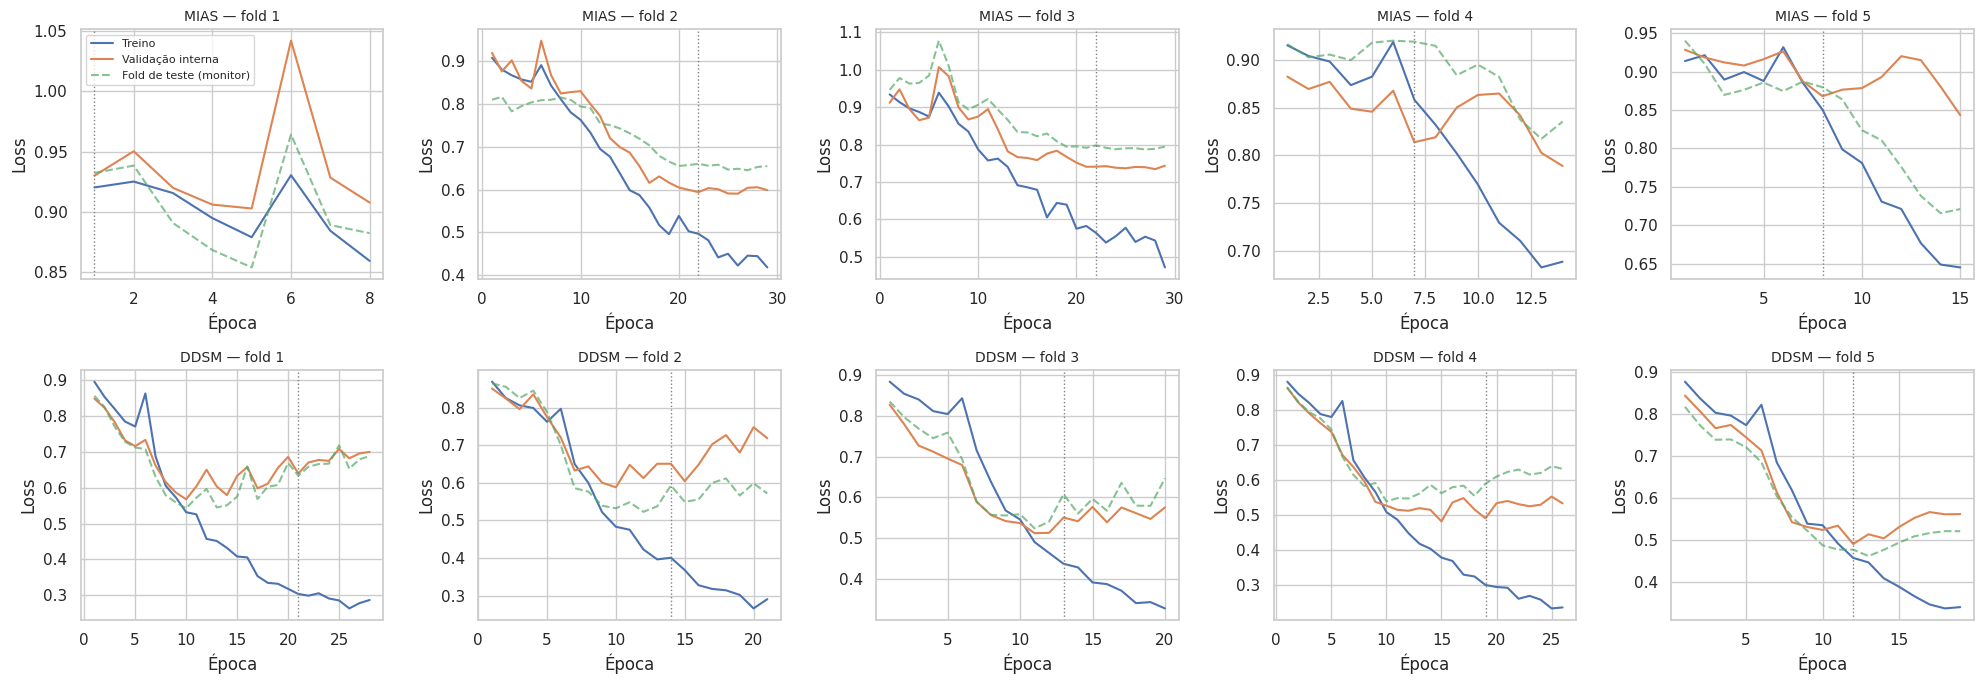

In [10]:
def run_experiment1(name, seed):
    d = DATA[name]
    X, y, g = d["X"], d["y"], d["groups"]
    outer = StratifiedGroupKFold(n_splits=CONFIG["N_SPLITS"], shuffle=True, random_state=seed)
    res = dict(folds=[], hist=[], oof=[])

    for fold, (tr_all, te) in enumerate(outer.split(X, y, g)):
        tr_in, va_in = group_holdout(y[tr_all], g[tr_all], seed + fold, CONFIG["INNER_VAL_FRAC"])
        tr, va = tr_all[tr_in], tr_all[va_in]
        # paciente em um só conjunto
        assert set(g[tr]).isdisjoint(g[va]) and set(g[tr]).isdisjoint(g[te]) and set(g[va]).isdisjoint(g[te])

        print(f"[{name}] fold {fold + 1}/{CONFIG['N_SPLITS']} | treino={len(tr)} val={len(va)} teste={len(te)}")
        model, hist = train_model(X, y, tr, va, seed + fold, mon_idx=te)

        p_va = predict_proba(model, X, y, va)
        thr = select_threshold(y[va], p_va)                  # limiar: validação interna
        p_te = predict_proba(model, X, y, te)
        m = compute_metrics(y[te], p_te, thr)

        b = hist.attrs["best_epoch"]
        row = hist[hist.epoch == b].iloc[0]
        m.update(dataset=name, fold=fold, best_epoch=b, gap_val_minus_train=row.val_loss - row.train_loss)
        res["folds"].append(m)
        res["hist"].append(hist)
        res["oof"].append(pd.DataFrame(dict(idx=te, y=y[te], p=p_te, pred=(p_te >= thr).astype(int),
                                            g=g[te], fold=fold)))
        print(f"  -> AUC={m['auc']:.3f} sens={m['sens']:.3f} spec={m['spec']:.3f} thr={thr:.3f}")
        del model
        if DEVICE.type == "cuda":
            torch.cuda.empty_cache()

    res["oof"] = pd.concat(res["oof"], ignore_index=True)
    return res


R1 = {}
for name in ["mias", "ddsm"]:
    R1[name] = run_experiment1(name, CONFIG["EXP1_SEED"])

with open(f"/content/drive/MyDrive/TCC/R1_resnet50_{CONFIG['POOLING']}_clahe.pkl", "wb") as fh:
    pickle.dump(R1, fh)

# ---- Resumo: média ± dp entre folds ----
for name in ["mias", "ddsm"]:
    folds = pd.DataFrame(R1[name]["folds"])
    print(f"\n=== Experimento 1 — {name.upper()} (média ± dp entre {CONFIG['N_SPLITS']} folds) ===")
    display(mean_std_table(R1[name]["folds"]).to_frame("valor"))
    print(f"Gap Val − Treino (loss, na melhor época): "
          f"{folds.gap_val_minus_train.mean():.3f} ± {folds.gap_val_minus_train.std():.3f}")
    display(folds[["fold", "best_epoch", "auc", "sens", "spec", "bal_acc", "f1", "precision", "thr",
                   "gap_val_minus_train"]].round(3))
    folds.to_csv(OUT / f"exp1_folds_{name}.csv", index=False)

# ---- Curvas de loss ----
fig, axes = plt.subplots(2, CONFIG["N_SPLITS"], figsize=(4 * CONFIG["N_SPLITS"], 7), squeeze=False)
for r, name in enumerate(["mias", "ddsm"]):
    for f, h in enumerate(R1[name]["hist"]):
        ax = axes[r, f]
        ax.plot(h.epoch, h.train_loss, label="Treino")
        ax.plot(h.epoch, h.val_loss, label="Validação interna")
        ax.plot(h.epoch, h.mon_loss, "--", alpha=0.7, label="Fold de teste (monitor)")
        ax.axvline(h.attrs["best_epoch"], color="gray", ls=":", lw=1)
        ax.set_title(f"{name.upper()} — fold {f + 1}", fontsize=10)
        ax.set_xlabel("Época")
        ax.set_ylabel("Loss")
        if r == 0 and f == 0:
            ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(OUT / "exp1_loss_curves.png", dpi=150)
plt.show()

## 7. Experimento 2: domain shift direto

Treina em um dataset e avalia no outro inteiro, nos dois sentidos (mias → ddsm e ddsm → mias). Para cada semente, a origem é dividida por paciente em treino e validação interna. O limiar vem só da origem. Nada do destino entra no treino, na escolha da época ou no limiar.

In [11]:
def run_experiment2(src, tgt):
    Xs, ys, gs = DATA[src]["X"], DATA[src]["y"], DATA[src]["groups"]
    Xt, yt = DATA[tgt]["X"], DATA[tgt]["y"]
    out = dict(probs={}, thr={}, metrics=[], src_val=[])

    for s in CONFIG["SEEDS"]:
        tr, va = group_holdout(ys, gs, s, CONFIG["INNER_VAL_FRAC"])
        assert set(gs[tr]).isdisjoint(gs[va])
        print(f"[{src} -> {tgt}] seed {s} | treino={len(tr)} val={len(va)} | alvo={len(yt)}")
        model, hist = train_model(Xs, ys, tr, va, s, mon_idx=None)

        p_va = predict_proba(model, Xs, ys, va)
        thr = select_threshold(ys[va], p_va)                          # limiar: origem
        p_t = predict_proba(model, Xt, yt, np.arange(len(yt)))        # alvo inteiro
        m = compute_metrics(yt, p_t, thr)
        m.update(seed=s, direction=f"{src}->{tgt}", best_epoch=hist.attrs["best_epoch"])
        out["metrics"].append(m)
        out["src_val"].append(compute_metrics(ys[va], p_va, thr))
        out["probs"][s], out["thr"][s] = p_t, thr
        print(f"  -> AUC alvo={m['auc']:.3f} sens={m['sens']:.3f} spec={m['spec']:.3f} thr(origem)={thr:.3f}")
        del model
        if DEVICE.type == "cuda":
            torch.cuda.empty_cache()
    return out


R2 = {}
for src, tgt in [("mias", "ddsm"), ("ddsm", "mias")]:
    R2[(src, tgt)] = run_experiment2(src, tgt)

with open(f"/content/drive/MyDrive/TCC/R2_resnet50_{CONFIG['POOLING']}_clahe.pkl", "wb") as fh:
    pickle.dump(R2, fh)

for (src, tgt), r in R2.items():
    print(f"\n=== Experimento 2 — {src.upper()} → {tgt.upper()} ({len(CONFIG['SEEDS'])} sementes) ===")
    df = pd.DataFrame(r["metrics"])
    display(df[["seed", "best_epoch", "auc", "sens", "spec", "bal_acc", "f1", "precision", "thr"]].round(3))
    display(mean_std_table(r["metrics"]).to_frame("média ± dp"))
    df.to_csv(OUT / f"exp2_{src}_to_{tgt}.csv", index=False)

[mias -> ddsm] seed 42 | treino=273 val=45 | alvo=3716
  ep 01 | fase=head_only | LR=3.0e-04,3.0e-04 | train 0.9075 | val 0.9213 | val AUC 0.645
  ep 02 | fase=head_only | LR=3.0e-04,3.0e-04 | train 0.8920 | val 0.8956 | val AUC 0.689
  ep 03 | fase=head_only | LR=2.9e-04,2.9e-04 | train 0.8815 | val 0.8771 | val AUC 0.727
  ep 04 | fase=head_only | LR=2.9e-04,2.9e-04 | train 0.8839 | val 0.8809 | val AUC 0.735
  ep 05 | fase=head_only | LR=2.8e-04,2.8e-04 | train 0.8657 | val 0.8662 | val AUC 0.742
  -> backbone descongelado; fine-tuning com LR discriminativa
  ep 06 | fase=fine_tuning | LR=1.0e-05,3.0e-04,3.0e-04,1.0e-05 | train 0.8948 | val 0.9981 | val AUC 0.508
  ep 07 | fase=fine_tuning | LR=9.8e-06,3.0e-04,3.0e-04,9.8e-06 | train 0.8687 | val 0.9446 | val AUC 0.580
  ep 08 | fase=fine_tuning | LR=9.6e-06,2.9e-04,2.9e-04,9.6e-06 | train 0.8141 | val 0.8734 | val AUC 0.679
  ep 09 | fase=fine_tuning | LR=9.4e-06,2.8e-04,2.8e-04,9.4e-06 | train 0.7928 | val 0.8783 | val AUC 0.662
 

,seed,best_epoch,auc,sens,spec,bal_acc,f1,precision,thr
0,42,11,0.607,0.216,0.917,0.566,0.315,0.584,0.527
1,123,19,0.649,0.259,0.929,0.594,0.373,0.663,0.558
2,999,25,0.638,0.417,0.775,0.596,0.455,0.501,0.388


,média ± dp
auc,0.631 ± 0.022
sens,0.297 ± 0.106
spec,0.873 ± 0.086
bal_acc,0.585 ± 0.017
f1,0.381 ± 0.070
precision,0.583 ± 0.081



=== Experimento 2 — DDSM → MIAS (3 sementes) ===


,seed,best_epoch,auc,sens,spec,bal_acc,f1,precision,thr
0,42,17,0.793,0.559,0.816,0.687,0.588,0.620,0.231
1,123,14,0.836,0.766,0.749,0.757,0.685,0.620,0.173
2,999,20,0.816,0.631,0.899,0.765,0.693,0.769,0.287


,média ± dp
auc,0.815 ± 0.021
sens,0.652 ± 0.105
spec,0.821 ± 0.075
bal_acc,0.736 ± 0.043
f1,0.655 ± 0.059
precision,0.670 ± 0.086


## 8. Análise

- **Drop** = AUC interno (Exp. 1) − AUC cruzado (Exp. 2).
- **IC 95 %:** bootstrap que reamostra pacientes, não imagens.
- **Predição cruzada agregada:** média das probabilidades entre sementes e média dos limiares de origem.
- **Limiar "oráculo":** usa rótulos do alvo. Só diagnóstico, não reportar como desempenho.

In [12]:
# ---- Bootstrap por paciente ----
def patient_bootstrap(y, p, groups, n_boot, seed):
    rng = np.random.RandomState(seed)
    ug, inv = np.unique(groups, return_inverse=True)
    by_g = [np.where(inv == i)[0] for i in range(len(ug))]
    vals = []
    for _ in range(n_boot):
        pick = rng.randint(0, len(ug), len(ug))
        idx = np.concatenate([by_g[i] for i in pick])
        if len(np.unique(y[idx])) < 2:
            continue
        vals.append(roc_auc_score(y[idx], p[idx]))
    return np.array(vals)


def ci95(v):
    return np.percentile(v, [2.5, 97.5])


# ---- Predições internas (OOF) e cruzadas (ensemble) ----
OOF = {n: R1[n]["oof"] for n in ["mias", "ddsm"]}
CROSS = {}
for (src, tgt), r in R2.items():
    p_ens = np.mean([r["probs"][s] for s in CONFIG["SEEDS"]], axis=0)
    thr_ens = float(np.mean([r["thr"][s] for s in CONFIG["SEEDS"]]))
    CROSS[(src, tgt)] = dict(p=p_ens, thr=thr_ens, y=DATA[tgt]["y"], g=DATA[tgt]["groups"])

# ---- Tabela de generalização ----
rows = []
for (src, tgt) in R2:
    folds = pd.DataFrame(R1[src]["folds"])
    auc_int_fold = folds.auc.mean()
    o = OOF[src]
    auc_int_pool = roc_auc_score(o.y, o.p)
    b_int = patient_bootstrap(o.y.values, o.p.values, o.g.values, CONFIG["N_BOOT"], CONFIG["BOOT_SEED"])

    c = CROSS[(src, tgt)]
    seed_aucs = np.array([m["auc"] for m in R2[(src, tgt)]["metrics"]])
    auc_cross_ens = roc_auc_score(c["y"], c["p"])
    b_cr = patient_bootstrap(c["y"], c["p"], c["g"], CONFIG["N_BOOT"], CONFIG["BOOT_SEED"] + 1)

    m = min(len(b_int), len(b_cr))
    b_drop = b_int[:m] - b_cr[:m]
    drop_seed = auc_int_fold - seed_aucs
    lo_i, hi_i = ci95(b_int)
    lo_c, hi_c = ci95(b_cr)
    lo_d, hi_d = ci95(b_drop)
    rows.append({
        "Sentido": f"{src.upper()} → {tgt.upper()}",
        "AUC interno (média folds ± dp)": f"{auc_int_fold:.3f} ± {folds.auc.std():.3f}",
        "AUC interno OOF [IC95%]": f"{auc_int_pool:.3f} [{lo_i:.3f}, {hi_i:.3f}]",
        "AUC cruzado (sementes ± dp)": f"{seed_aucs.mean():.3f} ± {seed_aucs.std(ddof=1) if len(seed_aucs) > 1 else 0:.3f}",
        "AUC cruzado ensemble [IC95%]": f"{auc_cross_ens:.3f} [{lo_c:.3f}, {hi_c:.3f}]",
        "Drop (média folds − sementes ± dp)": f"{drop_seed.mean():.3f} ± {drop_seed.std(ddof=1) if len(drop_seed) > 1 else 0:.3f}",
        "Drop (OOF − ensemble) [IC95%]": f"{auc_int_pool - auc_cross_ens:.3f} [{lo_d:.3f}, {hi_d:.3f}]",
    })
gen_table = pd.DataFrame(rows).set_index("Sentido")
display(gen_table.T)
gen_table.to_csv(OUT / "generalization_summary.csv")

Sentido,MIAS → DDSM,DDSM → MIAS
AUC interno (média folds ± dp),0.667 ± 0.123,0.907 ± 0.006
AUC interno OOF [IC95%],"0.682 [0.626, 0.737]","0.904 [0.892, 0.916]"
AUC cruzado (sementes ± dp),0.631 ± 0.022,0.815 ± 0.021
AUC cruzado ensemble [IC95%],"0.651 [0.627, 0.674]","0.845 [0.794, 0.894]"
Drop (média folds − sementes ± dp),0.035 ± 0.022,0.092 ± 0.021
Drop (OOF − ensemble) [IC95%],"0.031 [-0.029, 0.091]","0.058 [0.008, 0.110]"


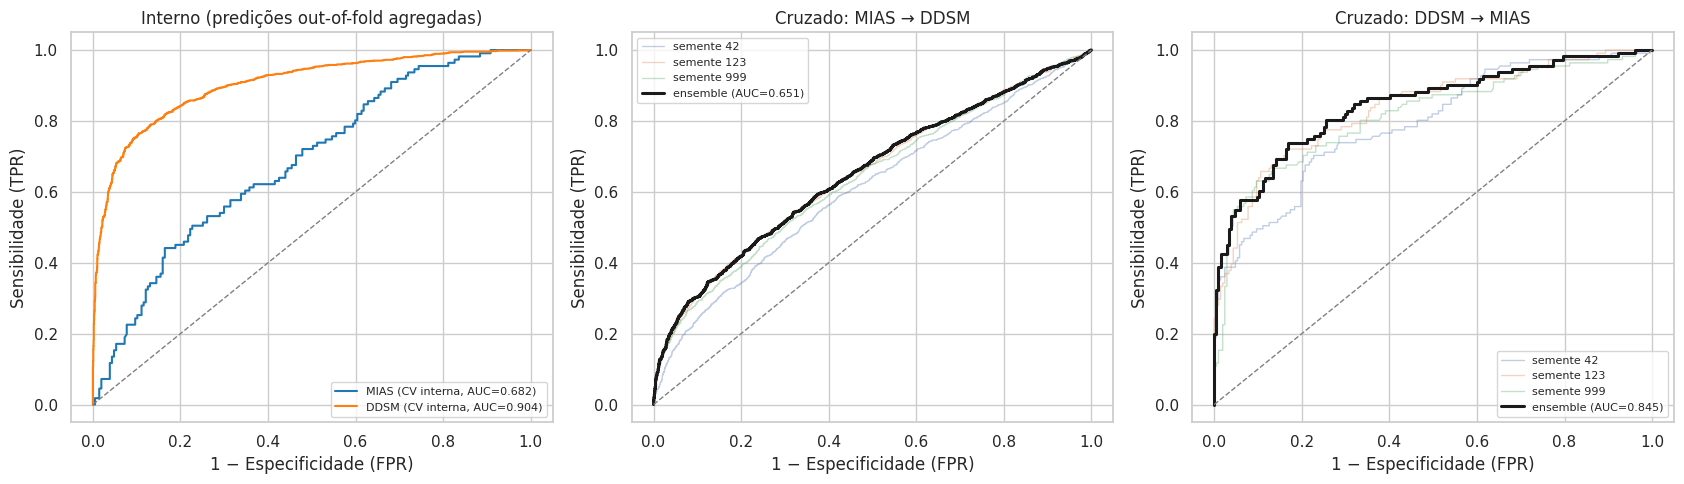

In [13]:
# ---- Curvas ROC ----
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

ax = axes[0]
for n, col in [("mias", "tab:blue"), ("ddsm", "tab:orange")]:
    o = OOF[n]
    fpr, tpr, _ = roc_curve(o.y, o.p)
    ax.plot(fpr, tpr, color=col, label=f"{n.upper()} (CV interna, AUC={roc_auc_score(o.y, o.p):.3f})")
ax.set_title("Interno (predições out-of-fold agregadas)")

for ax, (src, tgt) in zip(axes[1:], R2):
    c = CROSS[(src, tgt)]
    for s in CONFIG["SEEDS"]:
        fpr, tpr, _ = roc_curve(c["y"], R2[(src, tgt)]["probs"][s])
        ax.plot(fpr, tpr, alpha=0.35, lw=1, label=f"semente {s}")
    fpr, tpr, _ = roc_curve(c["y"], c["p"])
    ax.plot(fpr, tpr, "k", lw=2.2, label=f"ensemble (AUC={roc_auc_score(c['y'], c['p']):.3f})")
    ax.set_title(f"Cruzado: {src.upper()} → {tgt.upper()}")

for ax in axes:
    ax.plot([0, 1], [0, 1], "--", color="gray", lw=1)
    ax.set_xlabel("1 − Especificidade (FPR)")
    ax.set_ylabel("Sensibilidade (TPR)")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(OUT / "roc_curves.png", dpi=150)
plt.show()

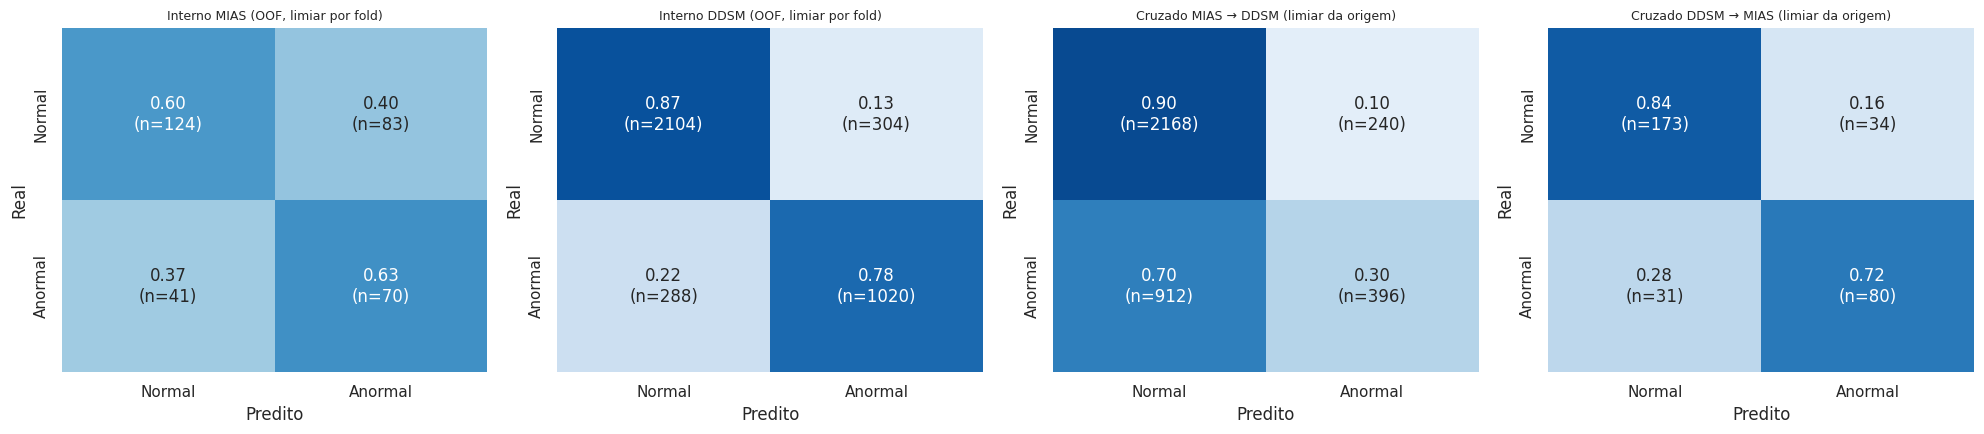

In [14]:
# ---- Matrizes de confusão ----
panels = [(f"Interno {n.upper()} (OOF, limiar por fold)", OOF[n].y.values, OOF[n].pred.values) for n in OOF]
panels += [(f"Cruzado {s.upper()} → {t.upper()} (limiar da origem)", CROSS[(s, t)]["y"],
            (CROSS[(s, t)]["p"] >= CROSS[(s, t)]["thr"]).astype(int)) for (s, t) in R2]

fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
for ax, (title, yt_, yp_) in zip(axes, panels):
    cm = confusion_matrix(yt_, yp_, labels=[0, 1])
    cmn = cm / cm.sum(axis=1, keepdims=True)
    annot = np.array([[f"{cmn[i, j]:.2f}\n(n={cm[i, j]})" for j in range(2)] for i in range(2)])
    sns.heatmap(cmn, annot=annot, fmt="", cmap="Blues", vmin=0, vmax=1, cbar=False, ax=ax,
                xticklabels=["Normal", "Anormal"], yticklabels=["Normal", "Anormal"])
    ax.set_title(title, fontsize=9)
    ax.set_xlabel("Predito")
    ax.set_ylabel("Real")
plt.tight_layout()
plt.savefig(OUT / "confusion_matrices.png", dpi=150)
plt.show()

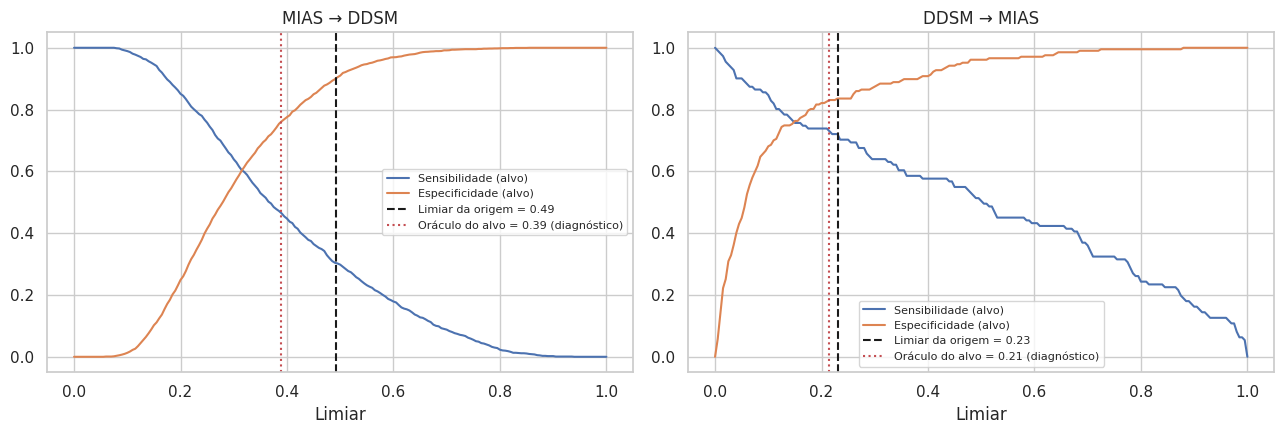

Sentido,MIAS → DDSM,DDSM → MIAS
Sens interna (origem),0.640,0.780
Esp interna (origem),0.595,0.874
Sens alvo @limiar origem,0.303,0.721
Esp alvo @limiar origem,0.900,0.836
Sens alvo @oráculo (diag.),0.468,0.739
Esp alvo @oráculo (diag.),0.761,0.831
Δ Sens (alvo − interna),-0.337,-0.059
Δ Esp (alvo − interna),0.305,-0.038



Arquivos salvos em: /content/drive/MyDrive/TCC/outputs_resnet50_clahe_roi_coif1_trainable


In [15]:
# ---- Deslocamento de limiar ----
ths = np.linspace(0, 1, 201)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
shift_rows = []
for ax, (src, tgt) in zip(axes, R2):
    c = CROSS[(src, tgt)]
    sens = [((c["p"] >= t) & (c["y"] == 1)).sum() / (c["y"] == 1).sum() for t in ths]
    spec = [((c["p"] < t) & (c["y"] == 0)).sum() / (c["y"] == 0).sum() for t in ths]
    ax.plot(ths, sens, label="Sensibilidade (alvo)")
    ax.plot(ths, spec, label="Especificidade (alvo)")
    ax.axvline(c["thr"], color="k", ls="--", label=f"Limiar da origem = {c['thr']:.2f}")
    t_or = select_threshold(c["y"], c["p"], "youden")   # só diagnóstico
    ax.axvline(t_or, color="r", ls=":", label=f"Oráculo do alvo = {t_or:.2f} (diagnóstico)")
    ax.set_title(f"{src.upper()} → {tgt.upper()}")
    ax.set_xlabel("Limiar")
    ax.legend(fontsize=8)

    internal = pd.DataFrame(R1[src]["folds"])
    mo = compute_metrics(c["y"], c["p"], c["thr"])
    mc = compute_metrics(c["y"], c["p"], t_or)
    shift_rows.append({"Sentido": f"{src.upper()} → {tgt.upper()}",
                       "Sens interna (origem)": internal.sens.mean(), "Esp interna (origem)": internal.spec.mean(),
                       "Sens alvo @limiar origem": mo["sens"], "Esp alvo @limiar origem": mo["spec"],
                       "Sens alvo @oráculo (diag.)": mc["sens"], "Esp alvo @oráculo (diag.)": mc["spec"]})
plt.tight_layout()
plt.savefig(OUT / "threshold_shift.png", dpi=150)
plt.show()

shift = pd.DataFrame(shift_rows).set_index("Sentido").round(3)
shift["Δ Sens (alvo − interna)"] = shift["Sens alvo @limiar origem"] - shift["Sens interna (origem)"]
shift["Δ Esp (alvo − interna)"] = shift["Esp alvo @limiar origem"] - shift["Esp interna (origem)"]
display(shift.T.round(3))
shift.to_csv(OUT / "threshold_shift.csv")
print(f"\nArquivos salvos em: {OUT.resolve()}")

## 9. Resumo das métricas

| Métrica | O que mede | Quando usar |
|---|---|---|
| **Acurácia** | Proporção de acertos gerais | Dados balanceados |
| **Precisão** | Confiabilidade das predições positivas | Evitar falsos positivos |
| **Recall** (sensibilidade) | Capacidade de encontrar positivos reais | Evitar falsos negativos |
| **F1-score** | Equilíbrio entre precisão e recall | Dados desbalanceados |
| **AUC-ROC** | Capacidade de separar as classes | Avaliação global do modelo |

In [16]:
# média ± dp entre folds (Exp. 1) ou sementes (Exp. 2)
COLS = {"acc": "Acurácia", "precision": "Precisão", "sens": "Recall", "f1": "F1-score", "auc": "AUC-ROC"}


def fmt(rows):
    df = pd.DataFrame(rows)[list(COLS)]
    return {v: f"{df[k].mean():.3f} ± {df[k].std():.3f}" for k, v in COLS.items()}


summary = {f"Exp. 1 — {n.upper()} (CV)": fmt(R1[n]["folds"]) for n in ["mias", "ddsm"]}
summary.update({f"Exp. 2 — {s.upper()} → {t.upper()}": fmt(r["metrics"]) for (s, t), r in R2.items()})
summary = pd.DataFrame(summary).T
display(summary)
summary.to_csv(OUT / "final_summary.csv")

,Acurácia,Precisão,Recall,F1-score,AUC-ROC
Exp. 1 — MIAS (CV),0.609 ± 0.115,0.469 ± 0.095,0.640 ± 0.185,0.529 ± 0.100,0.667 ± 0.123
Exp. 1 — DDSM (CV),0.841 ± 0.015,0.772 ± 0.032,0.780 ± 0.008,0.775 ± 0.016,0.907 ± 0.006
Exp. 2 — MIAS → DDSM,0.670 ± 0.022,0.583 ± 0.081,0.297 ± 0.106,0.381 ± 0.070,0.631 ± 0.022
Exp. 2 — DDSM → MIAS,0.762 ± 0.040,0.670 ± 0.086,0.652 ± 0.105,0.655 ± 0.059,0.815 ± 0.021
